# Download TWL&CC forecasts and build water-level time series

**Author:** Chelsea A. Volpano (cvolpano@gmail.com)
**Updated:** 2026-11-02, with Claude Opus 5.5 (Anthropic)

**Summary.** Downloads **every** USGS/NOAA Total Water Level and Coastal Change (TWL&CC) forecast issued
for one site (typically 2–4 per day), saves each as JSON named by issue time, then calls
`twl_json_to_timeseries.py` to build two CSVs:
- `*_all_forecasts_long.csv`: every hourly value of every forecast, with issue time and lead time.
- `*_best_estimate.csv`: one row per hour from the shortest-lead forecast; uncovered hours have `gap=True`.

**Datum and time.** Elevations are left in **m NAVD88** as delivered, so no VDatum shift is applied
(Birchler et al., 2024, https://doi.org/10.1016/j.coastaleng.2024.104590).
The source `dateTime` is **UTC**; outputs carry both UTC and America/New_York local time.

**Change log**
- 2026-11-02: Removed the LMSL→NAVD88 VDatum shift (the data are already in NAVD88).
  Removed the duplicate row appends and the keep-only-midnight step.
  Days already on disk are now skipped. The time-series step moved to `twl_json_to_timeseries.py`.
- 2026-11-02: Downloads every forecast issue per day via `twl_download.py`, not just the 00:00 issue that
  `utils_runup.fetch_water_level_data` took. This cuts best-estimate lead times from 0–23 h to about 0–11 h.
  Existing daily files are kept and treated as the 00:00 issue.

**Requires:** `twl_download.py` and `twl_json_to_timeseries.py` in the same folder as this notebook.

## 1. Settings
Edit these for a new site or date range.

In [1]:
import time
from pathlib import Path

import pandas as pd

from twl_download import download_forecasts
from twl_json_to_timeseries import LOCAL_TZ, process_folder

START_DATE = "2024-10-05"
END_DATE = "2024-12-31"
TWL_REGION = 1  # position in the API region list (1 = Boston, MA)
SITE_ID = 1548
LAT, LON = 41.897136303912966, -69.96233057531904  # site location, for reference
SAVE_FOLDER = Path("../DATA/data_wl")
PAUSE_S = 1.0  # pause between API calls to stay under the rate limit

## 2. Download every forecast issue
For each date, the API lists every forecast issued that day (e.g. 00:00, 06:00, 12:00 UTC). Each issue is saved as
`<Region>_<site>_<YYYY-MM-DD>T<HHMM>.json`. Issues already on disk are skipped, including your older daily files,
which are the 00:00 issue, so re-running only fetches what's missing. A catalog of every issue and its status is
saved as `*_forecast_catalog.csv`. Expect about 4 requests per day (1 list plus about 3 issues), around 7 minutes for
Dec–Mar at 1 s pacing.

In [2]:
catalog = download_forecasts(START_DATE, END_DATE, TWL_REGION, SITE_ID,
                             SAVE_FOLDER, pause_s=PAUSE_S)
catalog.tail(10)

Region: Boston, MA (id 1), site 1548
2024-10-05 00:00:00: saved Boston,_MA_1548_2024-10-05T0000.json
2024-10-05 06:00:00: saved Boston,_MA_1548_2024-10-05T0600.json
2024-10-06: no forecasts listed
2024-10-07: no forecasts listed
2024-10-08 00:00:00: saved Boston,_MA_1548_2024-10-08T0000.json
2024-10-08 06:00:00: saved Boston,_MA_1548_2024-10-08T0600.json
2024-10-08 12:00:00: saved Boston,_MA_1548_2024-10-08T1200.json
2024-10-09 00:00:00: saved Boston,_MA_1548_2024-10-09T0000.json
2024-10-09 06:00:00: saved Boston,_MA_1548_2024-10-09T0600.json
2024-10-09 12:00:00: saved Boston,_MA_1548_2024-10-09T1200.json
2024-10-10 00:00:00: saved Boston,_MA_1548_2024-10-10T0000.json
2024-10-10 06:00:00: saved Boston,_MA_1548_2024-10-10T0600.json
2024-10-10 12:00:00: saved Boston,_MA_1548_2024-10-10T1200.json
2024-10-11 00:00:00: saved Boston,_MA_1548_2024-10-11T0000.json
2024-10-11 06:00:00: saved Boston,_MA_1548_2024-10-11T0600.json
2024-10-11 12:00:00: saved Boston,_MA_1548_2024-10-11T1200.json
202

,date,time,forecast_id,max_impact,file,status
459,2025-03-11,12:00:00,91047,Collision,"Boston,_MA_1548_2025-03-11T1200.json",on disk
460,2025-03-12,00:00:00,91066,Collision,"Boston,_MA_1548_2025-03-12.json",on disk
461,2025-03-12,06:00:00,91076,Collision,"Boston,_MA_1548_2025-03-12T0600.json",on disk
462,2025-03-12,12:00:00,91091,Collision,"Boston,_MA_1548_2025-03-12T1200.json",on disk
463,2025-03-13,00:00:00,91109,Collision,"Boston,_MA_1548_2025-03-13.json",on disk
464,2025-03-13,06:00:00,91118,Collision,"Boston,_MA_1548_2025-03-13T0600.json",on disk
465,2025-03-13,12:00:00,91131,Collision,"Boston,_MA_1548_2025-03-13T1200.json",on disk
466,2025-03-14,00:00:00,91153,Collision,"Boston,_MA_1548_2025-03-14.json",on disk
467,2025-03-14,06:00:00,91162,Collision,"Boston,_MA_1548_2025-03-14T0600.json",on disk
468,2025-03-14,12:00:00,91179,Collision,"Boston,_MA_1548_2025-03-14T1200.json",on disk


## 3. Build the time series
Reads every JSON in the folder, then writes the long and best-estimate CSVs and a README to `SAVE_FOLDER`.
To use only day-1 forecasts, pass `max_lead_hours=23`.

In [3]:
long_df, best_df = process_folder(SAVE_FOLDER)
best_df.head()

TWL closure check: 0 of 35670 rows exceed 0.021 m (max |resid| = 0.000 m)
Read 246 files -> 35670 forecast rows, 2245 hourly rows (0 gap hours)
Saved to C:\Users\cvolp\shorescan_processing\DATA\data_wl as Boston,_MA_1548_20241004-20250106_*.csv


,valid_time_local,valid_time_utc,lead_hours,gap,issue_time_local,issue_time_utc,id,twl,twl05,twl95,...,runup05,runup95,tideWindSetup,swash,incSwash,infragSwash,hs,pp,predictedImpact,predictedImpactCode
0,2024-10-04 20:00:00-04:00,2024-10-05 00:00:00+00:00,0,False,2024-10-04 20:00:00-04:00,2024-10-05 00:00:00+00:00,2.930694e+09,-1.08,-1.10,-1.07,...,0.04,0.07,-1.11,0.05,0.04,0.04,0.09,1.5748,None,0.0
1,2024-10-04 21:00:00-04:00,2024-10-05 01:00:00+00:00,1,False,2024-10-04 20:00:00-04:00,2024-10-05 00:00:00+00:00,2.930694e+09,-0.44,-0.56,-0.32,...,0.29,0.52,-0.69,0.43,0.32,0.29,0.14,10.2697,None,0.0
2,2024-10-04 22:00:00-04:00,2024-10-05 02:00:00+00:00,2,False,2024-10-04 20:00:00-04:00,2024-10-05 00:00:00+00:00,2.930694e+09,0.18,0.02,0.36,...,0.43,0.77,-0.19,0.64,0.47,0.43,0.32,10.1645,None,0.0
3,2024-10-04 23:00:00-04:00,2024-10-05 03:00:00+00:00,3,False,2024-10-04 20:00:00-04:00,2024-10-05 00:00:00+00:00,2.930694e+09,0.73,0.54,0.93,...,0.48,0.87,0.31,0.72,0.53,0.48,0.40,10.0944,None,0.0
4,2024-10-05 00:00:00-04:00,2024-10-05 04:00:00+00:00,4,False,2024-10-04 20:00:00-04:00,2024-10-05 00:00:00+00:00,2.930694e+09,1.16,0.96,1.38,...,0.50,0.92,0.72,0.75,0.56,0.51,0.45,10.0727,None,0.0


## 4. Quick-look plot
Top: best-estimate TWL with its 5–95% range, plus tide + surge + wave setup. Grey shading marks gap hours.
Bottom: the lead time used for each hour, so you can see where older forecasts filled missing issues.

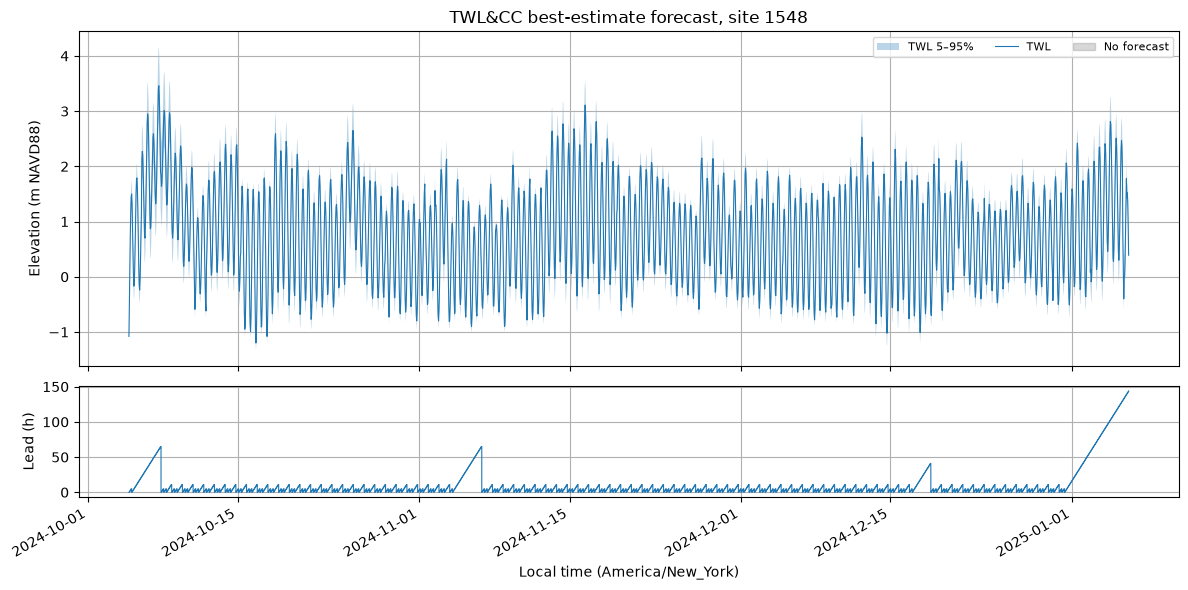

In [4]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

t = best_df["valid_time_local"]
startT = t.min().strftime("%Y%m%d")
endT = t.max().strftime("%Y%m%d")
fig, (ax, ax_lead) = plt.subplots(2, 1, figsize=(12, 6), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1]})

ax.fill_between(t, best_df["twl05"], best_df["twl95"], alpha=0.3, label="TWL 5–95%")
ax.plot(t, best_df["twl"], lw=0.8, label="TWL")
#ax.plot(t, best_df["tideWindSetup"], lw=0.8, label="Tide + surge + setup")
# Shade gap hours across the full height in one call (no loop over gaps).
ax.fill_between(t, 0, 1, where=best_df["gap"], color="grey", alpha=0.3,
                transform=ax.get_xaxis_transform(), label="No forecast")
ax.set_ylabel("Elevation (m NAVD88)")
ax.set_title(f"TWL&CC best-estimate forecast, site {SITE_ID}")
ax.legend(loc="upper right", ncol=4, fontsize=8)
ax.grid()

ax_lead.step(t, best_df["lead_hours"].astype(float), where="post", lw=0.8)
ax_lead.set_ylabel("Lead (h)")
ax_lead.set_xlabel(f"Local time ({LOCAL_TZ})")
# Without tz=, matplotlib labels tz-aware times in UTC.
ax_lead.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d", tz=LOCAL_TZ))
ax_lead.grid()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(f"../twl_forecast_{SITE_ID}_{startT}-{endT}.png", dpi=300)
plt.show()

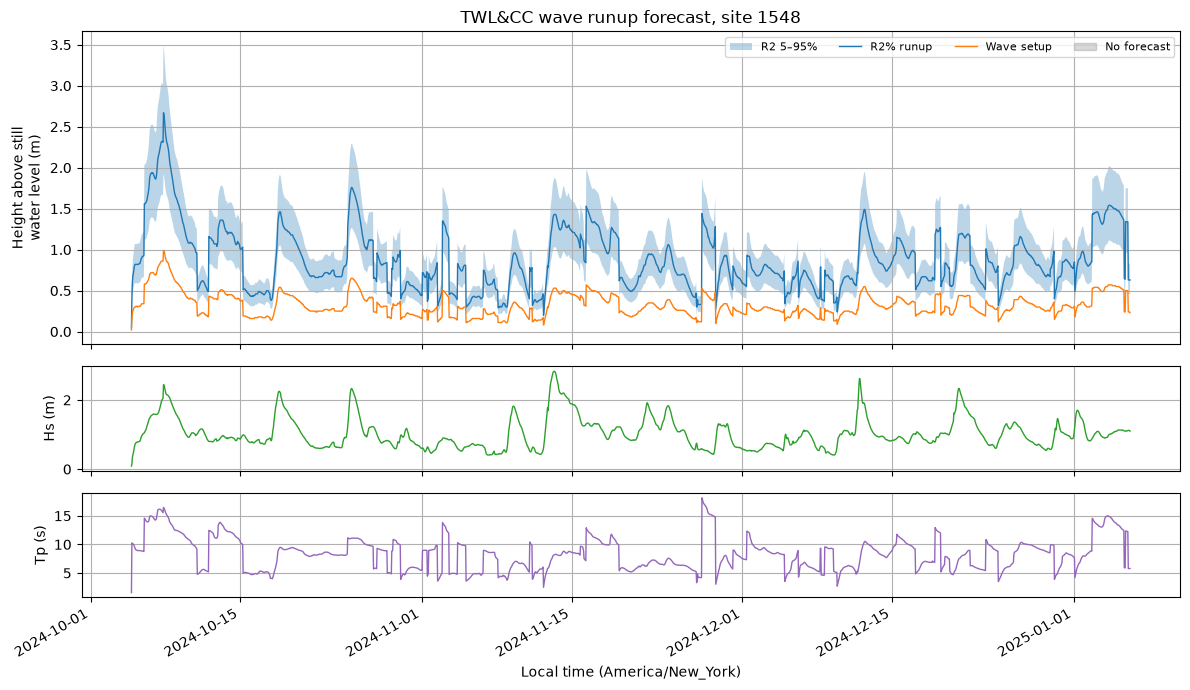

In [5]:
# --- Wave runup (R2%) from the TWL&CC best-estimate series ---
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

PLOT_START, PLOT_END = None, None  # e.g. "2024-12-15", "2024-12-25" (local); None = all

# Load the best-estimate CSV if the notebook wasn't run top to bottom.
if "best_df" not in globals():
    csv = sorted(SAVE_FOLDER.glob("*_best_estimate.csv"))[-1]
    best_df = pd.read_csv(csv, keep_default_na=False, na_values=[""])
    best_df["valid_time_local"] = (pd.to_datetime(best_df["valid_time_utc"], utc=True)
                                   .dt.tz_convert(LOCAL_TZ))

# Select the plot window with one boolean mask (no loop over rows).
t_all = best_df["valid_time_local"]
mask = pd.Series(True, index=best_df.index)
if PLOT_START:
    mask &= t_all >= pd.Timestamp(PLOT_START, tz=LOCAL_TZ)
if PLOT_END:
    mask &= t_all < pd.Timestamp(PLOT_END, tz=LOCAL_TZ)
df = best_df[mask]
t = df["valid_time_local"]

fig, (ax_r, ax_h, ax_p) = plt.subplots(3, 1, figsize=(12, 7), sharex=True,
                                       gridspec_kw={"height_ratios": [3, 1, 1]})

# Top: R2% runup with its 5-95% range (from beach-slope uncertainty), and setup.
ax_r.fill_between(t, df["runup05"], df["runup95"], alpha=0.3, label="R2 5–95%")
ax_r.plot(t, df["runup"], lw=1, label="R2% runup")
ax_r.plot(t, df["setup"], lw=1, label="Wave setup")
ax_r.set_ylabel("Height above still\nwater level (m)")
ax_r.set_title(f"TWL&CC wave runup forecast, site {SITE_ID}")

# Lower panels: the offshore wave forcing that drives runup.
ax_h.plot(t, df["hs"], lw=1, color="tab:green")
ax_h.set_ylabel("Hs (m)")
ax_p.plot(t, df["pp"], lw=1, color="tab:purple")
ax_p.set_ylabel("Tp (s)")

# Shade hours with no forecast on every panel.
for ax in (ax_r, ax_h, ax_p):
    ax.fill_between(t, 0, 1, where=df["gap"], color="grey", alpha=0.3,
                    transform=ax.get_xaxis_transform(),
                    label="No forecast" if ax is ax_r else None)
    ax.grid()
ax_r.legend(loc="upper right", ncol=4, fontsize=8)

ax_p.set_xlabel(f"Local time ({LOCAL_TZ})")
ax_p.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d", tz=LOCAL_TZ))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(f"../twl_runup_{SITE_ID}_{startT}-{endT}.png", dpi=300)
plt.show()